In [1]:
#install and load all packages needed for getting text classification workflow set up

#to check for packages, install if missing
import importlib
import subprocess
import sys
import time

def install_and_import(package, pip_name=None):
    """
    Try importing a package, and install it if not available.
    """
    try:
        return importlib.import_module(package)
    except ImportError:
        name_to_install = pip_name if pip_name else package
        print(f"Installing missing package: {name_to_install} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", name_to_install])
        return importlib.import_module(package)


# ---- Import (or install) required packages ----
pd = install_and_import("pandas")
sklearn = install_and_import("sklearn", "scikit-learn")
tqdm = install_and_import("tqdm")
matplotlib = install_and_import("matplotlib")
seaborn = install_and_import("seaborn")
tensorflow = install_and_import("tensorflow")
tiktoken = install_and_import("tiktoken")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from tqdm import tqdm

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import seaborn as sns
import gensim #may require virtual environment or setting python to previous version
from gensim.models import Word2Vec, FastText

#testing word embeddings
sentences = [["gensim", "is", "working"], ["vector", "test", "example"]]
w2v = Word2Vec(sentences, vector_size=20, min_count=1, window=2)
print("Word2Vec example:", w2v.wv["gensim"])

ft = FastText(sentences, vector_size=20, min_count=1, window=2)
print("FastText example:", ft.wv["gensim"])

#load small pretrained model
import gensim.downloader as api
w2v_model = api.load("glove-wiki-gigaword-50")  # small, fast model
fasttext_model = api.load("fasttext-wiki-news-subwords-300")

# For RNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from scikeras.wrappers import KerasClassifier

import os
import re

from sklearn.base import BaseEstimator, ClassifierMixin
from difflib import get_close_matches

from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold


Word2Vec example: [-0.04309844  0.01832869  0.02594942  0.02870969  0.03733459 -0.03083838
  0.00552807  0.03023641 -0.01420025 -0.03086761 -0.00205112 -0.04184474
 -0.02800006  0.03552269  0.0167627   0.03612835  0.03400124  0.03765371
 -0.01894577 -0.00280903]
FastText example: [-0.0105756  -0.00166513  0.00106871 -0.00028702 -0.00111164 -0.00494283
 -0.00285465 -0.00431463  0.0009634  -0.00533322  0.00647987  0.00450186
  0.0004346  -0.00173723 -0.00220466  0.00477369  0.00897229 -0.00644282
  0.01039309  0.00056901]


## Import Training Data

In [2]:
#import open-source text classification datasets
#https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset

# # # move datasets to shared space or just link. remove my path:

ag_dataset_test = pd.read_csv(r"/Users/robertheld/.cache/kagglehub/datasets/amananandrai/ag-news-classification-dataset/versions/2/test.csv")
ag_dataset_train = pd.read_csv(r"/Users/robertheld/.cache/kagglehub/datasets/amananandrai/ag-news-classification-dataset/versions/2/train.csv")

In [ ]:
#check if training data is intact 
#revert html adaptations
import pandas as pd
import html

# Example DataFrame
df = pd.DataFrame({
    "text": [
        "But that optimism isn #39;t matched by Infineo...",
        "It #39;s a good day &amp; we #39;re ready to go!"
    ]
})

# Clean all rows
df["text_cleaned"] = df["text"].apply(html.unescape)

In [17]:
#train_texts = ag_dataset_train["Description"]
#train_labels = ag_dataset_train["Class Index"]
#test_texts = ag_dataset_test["Description"]
#test_labels = ag_dataset_test["Class Index"]

In [53]:
#sample training data to speed up testing vec mod combinations

from sklearn.utils import resample

def sample_per_label(df, label_col, n_samples=100, random_state=42):
    """
    Returns a DataFrame containing `n_samples` rows for each unique label in `label_col`.
    If a label has fewer than n_samples, it will return all rows for that label.
    """
    sampled_dfs = []
    labels = df[label_col].unique()
    
    for label in labels:
        df_label = df[df[label_col] == label]
        if len(df_label) > n_samples:
            df_sampled = resample(df_label, n_samples=n_samples, replace=False, random_state=random_state)
        else:
            df_sampled = df_label.copy()
        sampled_dfs.append(df_sampled)
    
    return pd.concat(sampled_dfs).reset_index(drop=True)


In [54]:
# Take 3000 rows per label for training statistical models
train_sampled = sample_per_label(ag_dataset_train, label_col="Class Index", n_samples=3000)

# Separate features/labels for pipeline
stat_sampled_train_texts = train_sampled["Description"].tolist()
stat_sampled_train_labels = train_sampled["Class Index"].tolist()

In [55]:
# Take 10 rows per label for training llm models
# which will be adjusted per n-shot iteration
# max 10
train_sampled = sample_per_label(ag_dataset_train, label_col="Class Index", n_samples=10)

# Separate features/labels for pipeline
llm_sampled_train_texts = train_sampled["Description"].tolist()
llm_sampled_train_labels = train_sampled["Class Index"].tolist()

In [93]:
# Take 25 rows per label for testing all variants for 1:1 comparison (n = 100)
test_sampled = sample_per_label(ag_dataset_test, label_col="Class Index", n_samples=25)

# Separate features/labels for pipeline
sampled_test_texts = test_sampled["Description"].tolist()
sampled_test_labels = test_sampled["Class Index"].tolist()

In [120]:
# Take 250 rows per label for testing ensemble with llm boost (n = 1000)
test_sampled = sample_per_label(ag_dataset_test, label_col="Class Index", n_samples=250)

# Separate features/labels for pipeline
sampled_test_texts_n1000 = test_sampled["Description"].tolist()
sampled_test_labels_n1000 = test_sampled["Class Index"].tolist()

In [94]:
print(len(stat_sampled_train_texts))
print(len(stat_sampled_train_labels))
print(len(llm_sampled_train_texts))
print(len(llm_sampled_train_labels))
print(len(sampled_test_texts))
print(len(sampled_test_labels))

12000
12000
40
40
100
100


In [80]:
#create one-shot and few shot 5 using consistent training data with few shot 10
df_temp = pd.DataFrame({
    "label": llm_sampled_train_labels,
    "text": llm_sampled_train_texts
})

# Determine how many examples per class (based on total / num classes)
unique_classes = df_temp["label"].unique()
n_classes = len(unique_classes)
examples_per_class = len(df_temp) // n_classes

# --- One-shot: pick first example of each class (0, 10, 20, 30, ...) ---
os_indices = [i * examples_per_class for i in range(n_classes)]
os_sampled_df = df_temp.iloc[os_indices]

os_sampled_train_labels = os_sampled_df["label"].tolist()
os_sampled_train_texts = os_sampled_df["text"].tolist()

# --- Five-shot: pick first 5 examples of each class (0–4, 10–14, 20–24, ...) ---
fs_indices = np.concatenate([
    np.arange(i * examples_per_class, i * examples_per_class + 5)
    for i in range(n_classes)
])
fs_sampled_df = df_temp.iloc[fs_indices]

fs_sampled_train_labels = fs_sampled_df["label"].tolist()
fs_sampled_train_texts = fs_sampled_df["text"].tolist()

#confirm: 
print("One-shot indices:", os_indices)
print("Five-shot indices:", fs_indices)
print("\nOne-shot counts:", os_sampled_df['label'].value_counts().to_dict())
print("Five-shot counts:", fs_sampled_df['label'].value_counts().to_dict())


One-shot indices: [0, 10, 20, 30]
Five-shot indices: [ 0  1  2  3  4 10 11 12 13 14 20 21 22 23 24 30 31 32 33 34]

One-shot counts: {3: 1, 4: 1, 2: 1, 1: 1}
Five-shot counts: {3: 5, 4: 5, 2: 5, 1: 5}


In [88]:
#faster method: use sample_per_label() to get repeated samples across llm variations

#sample_per_label(ag_dataset_train, label_col="Class Index", n_samples=5)

## Statistical Classification Methods

In [134]:
## Statistical Class Method

# ---- Embedding vectorizer wrapper ----
class EmbeddingVectorizer(BaseEstimator, TransformerMixin):
    """
    Converts text documents into mean embeddings using a pre-trained gensim model.
    Works with both Word2Vec/FastText 
    """
    def __init__(self, embedding_model, lowercase=True):
        self.embedding_model = embedding_model
        self.lowercase = lowercase
        # Handle both gensim model and KeyedVectors
        self.is_keyed_vectors = not hasattr(embedding_model, "wv")
        self.dim = embedding_model.vector_size

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        vectors = []
        for doc in X:
            # Optionally normalize casing for consistency
            words = doc.lower().split() if self.lowercase else doc.split()

            if self.is_keyed_vectors:
                # For KeyedVectors (e.g., GloVe)
                vecs = [self.embedding_model[w] for w in words if w in self.embedding_model]
            else:
                # For full Word2Vec or FastText models
                vecs = [self.embedding_model.wv[w] for w in words if w in self.embedding_model.wv]

            # Average vectors in a document, or use zeros if no known words
            if vecs:
                vectors.append(np.mean(vecs, axis=0))
            else:
                vectors.append(np.zeros(self.dim))
        return np.array(vectors)


# ---- Main pipeline class ----
class TextClassificationPipeline:
    def __init__(self, train_texts, train_labels, test_texts, test_labels,
                 pretrained_word2vec_model=None, pretrained_glove_model=None, pretrained_fasttext_model=None,
                 max_seq_len=100, vocab_size=10000):
        self.train_texts = train_texts
        self.train_labels = train_labels
        self.test_texts = test_texts
        self.test_labels = test_labels
        self.max_seq_len = max_seq_len
        self.vocab_size = vocab_size
        
        # Vectorizers
        self.vectorizers = {
            "BoW": CountVectorizer(stop_words="english"),
            "BoW (2-grams)": CountVectorizer(ngram_range=(1,2), stop_words="english"),
            "TF-IDF": TfidfVectorizer(stop_words="english"),
            "TF-IDF (2-grams)": TfidfVectorizer(ngram_range=(1,2), stop_words="english"),
            "Hashing": HashingVectorizer(n_features=2**16)
        }
        if pretrained_word2vec_model:
            self.vectorizers["Word2Vec"] = EmbeddingVectorizer(pretrained_word2vec_model)
        #if pretrained_glove_model:
        #    self.vectorizers["GloVe"] = EmbeddingVectorizer(pretrained_glove_model)
        if pretrained_fasttext_model:
            self.vectorizers["FastText"] = EmbeddingVectorizer(pretrained_fasttext_model)
        
        # Models
        self.models = {
            "Logistic Regression": LogisticRegression(max_iter=1000),
            "Naive Bayes": MultinomialNB(),
            "SVM": SVC(),
            "Random Forest": RandomForestClassifier(n_estimators=100)        
        }


    # ---- Run experiments ----
    def run_experiments(self, plot_cm=False):
        print("\n=== Label distribution in training data ===")
        label_counts = pd.Series(self.train_labels).value_counts()
        print(label_counts.to_string())
        print("==========================================\n")
    
        start_total = time.time()
        results = []
        mistakes_records = []
        fp_fn_matrix_records = []
        confusion_matrices = {}
    
        combinations = [(v_name, m_name) for v_name in self.vectorizers for m_name in self.models]
    
        with tqdm(total=len(combinations), desc="Running experiments", ncols=100) as pbar:
            for vec_name, model_name in combinations:

                vectorizer = self.vectorizers[vec_name]
                model = self.models[model_name]
    
                # ---- Skip MultinomialNB for any vectorizer that may produce negative values ----
                if model_name == "Naive Bayes":
                    # CountVectorizer is safe; all others may produce negative values
                    if vec_name not in ["BoW", "BoW (2-grams)"]:
                        pbar.update(1)
                        continue
    
                start_time = time.time()
                pipeline = Pipeline([
                    ("vectorizer", vectorizer),
                    ("classifier", model)
                ])
                pipeline.fit(self.train_texts, self.train_labels)
                preds = pipeline.predict(self.test_texts)
    
                # ---- Metrics ----
                acc = accuracy_score(self.test_labels, preds)
                prec = precision_score(self.test_labels, preds, average="weighted", zero_division=0)
                rec = recall_score(self.test_labels, preds, average="weighted", zero_division=0)
                f1 = f1_score(self.test_labels, preds, average="weighted", zero_division=0)
                elapsed = time.time() - start_time
    
                # ---- Confusion matrix ----
                labels_sorted = sorted(set(self.test_labels))
                cm = confusion_matrix(self.test_labels, preds, labels=labels_sorted)
                confusion_matrices[f"{vec_name} + {model_name}"] = cm
    
                if plot_cm:
                    disp = ConfusionMatrixDisplay(cm, display_labels=labels_sorted)
                    disp.plot(cmap=plt.cm.Blues)
                    plt.title(f"Confusion Matrix: {vec_name} + {model_name}")
                    plt.show()
    
                # ---- FP/FN per label ----
                fp = cm.sum(axis=0) - cm.diagonal()
                fn = cm.sum(axis=1) - cm.diagonal()
                total_misclassified = int(fp.sum())
                error_rate = total_misclassified / len(self.test_labels)
    
                for i, label in enumerate(labels_sorted):
                    fp_fn_matrix_records.append({
                        "Vectorizer": vec_name,
                        "Model": model_name,
                        "Label": label,
                        "False Positives": int(fp[i]),
                        "False Negatives": int(fn[i])
                    })
    
                # ---- FP/FN examples ----
                comparison_df = pd.DataFrame({
                    "text": self.test_texts,
                    "true_label": self.test_labels,
                    "predicted_label": preds
                })
                fp_examples = comparison_df[
                    (comparison_df["predicted_label"] != comparison_df["true_label"]) &
                    (comparison_df["predicted_label"].isin(labels_sorted))
                ]
                fn_examples = comparison_df[
                    (comparison_df["predicted_label"] != comparison_df["true_label"]) &
                    (comparison_df["true_label"].isin(labels_sorted))
                ]
                mistakes_records.append({
                    "Vectorizer": vec_name,
                    "Model": model_name,
                    "False Positive Examples": fp_examples,
                    "False Negative Examples": fn_examples
                })
    
                # ---- Summary results ----
                results.append({
                    "Vectorizer": vec_name,
                    "Model": model_name,
                    "Accuracy": acc,
                    "Precision": prec,
                    "Recall": rec,
                    "F1-score": f1,
                    "Misclassifications": total_misclassified,
                    "Error Rate": error_rate,
                    "Runtime (s)": elapsed
                })
    
                pbar.update(1)

        return results, mistakes_records, fp_fn_matrix_records, confusion_matrices

    def run_learning_curve(
        self,
        train_sizes=None,
        #metrics=["Accuracy", "F1-score"],
        metrics=["F1-score"],
        plot_live=True,
        selected_vectorizers=None,
        selected_models=None,
        selected_combinations=None
    ):
        """
        train_sizes : list of int
            Number of training rows per label to use at each iteration.
        metrics : list
            Metrics to track ("Accuracy", "F1-score").
        plot_live : bool
            Whether to show live plot in notebook.
        selected_vectorizers : list[str], optional
            Names of vectorizers to include (subset of self.vectorizers.keys()).
        selected_models : list[str], optional
            Names of models to include (subset of self.models.keys()).
        selected_combinations : list[tuple(str, str)], optional
            Explicit (vectorizer, model) pairs to evaluate. Overrides the two filters above.
            
        Returns:
        learning_results : dict
            Keys = combination names, values = list of metrics per train size.
        """
        import numpy as np
        from sklearn.utils import resample
        from sklearn.metrics import accuracy_score, f1_score
        from IPython.display import clear_output, display
        import matplotlib.pyplot as plt
        from tqdm import tqdm
    
        if train_sizes is None:
            train_sizes = [100, 500, 1000, 2000]
    
        # --- Determine which vectorizers and models to use ---
        vectorizers_to_use = (
            selected_vectorizers if selected_vectorizers else list(self.vectorizers.keys())
        )
        models_to_use = (
            selected_models if selected_models else list(self.models.keys())
        )
    
        # --- Define combinations ---
        if selected_combinations:
            combos = selected_combinations
        else:
            combos = [(v, m) for v in vectorizers_to_use for m in models_to_use]
    
        # --- Initialize results dict ---
        learning_results = {f"{v} + {m}": [] for v, m in combos}
    
        labels_sorted = sorted(set(self.train_labels))
    
        # --- Main loop over training sizes ---
        for size in tqdm(train_sizes, desc="Training sizes"):
            X_sub, y_sub = [], []
            for label in labels_sorted:
                X_label = [x for x, y_ in zip(self.train_texts, self.train_labels) if y_ == label]
                y_label = [y_ for y_ in self.train_labels if y_ == label]
    
                # sample per class
                if len(X_label) >= size:
                    X_sample, y_sample = resample(X_label, y_label, n_samples=size, replace=False, random_state=42)
                else:
                    X_sample, y_sample = X_label, y_label  # use all available
    
                X_sub.extend(X_sample)
                y_sub.extend(y_sample)
    
            # --- Train each combo ---
            for vec_name, model_name in combos:
    
                # Skip Naive Bayes + non-BoW vectorizers
                if model_name == "Naive Bayes" and vec_name not in ["BoW", "BoW (2-grams)"]:
                    continue
    
                pipeline = Pipeline([
                    ("vectorizer", self.vectorizers[vec_name]),
                    ("classifier", self.models[model_name])
                ])
    
                pipeline.fit(X_sub, y_sub)
                preds = pipeline.predict(self.test_texts)
    
                # Metrics
                acc = accuracy_score(self.test_labels, preds)
                f1 = f1_score(self.test_labels, preds, average="weighted", zero_division=0)
    
                combo_key = f"{vec_name} + {model_name}"
                learning_results[combo_key].append({"TrainSize": size, "Accuracy": acc, "F1-score": f1})
    
            # --- Live plotting ---
            if plot_live:
                clear_output(wait=True)
                fig, ax = plt.subplots(figsize=(10, 6))
                for combo_key, data in learning_results.items():
                    if not data:
                        continue
                    sizes = [d["TrainSize"] for d in data]
                    #acc_values = [d["Accuracy"] for d in data]
                    f1_values = [d["F1-score"] for d in data]
                    #ax.plot(sizes, acc_values, marker='o', label=f"{combo_key} Accuracy") #toggle one to show 2 metrics per combo
                    ax.plot(sizes, f1_values, marker='x', linestyle='--', label=f"{combo_key} F1")
                ax.set_xlabel("Training rows per label")
                ax.set_ylabel("Metric")
                ax.set_title("Learning Curves (live update)")
                ax.legend(fontsize=8)
                
                # Force the y-axis from 0 to 1
                ax.relim()
                ax.autoscale(False)
                ax.set_ylim(0, 1)
                fig.canvas.draw_idle()
                
                display(fig)
                
                # === Save frame for GIF ===
                fig.savefig(f"learning_curve_frame_{size}.png", dpi=150, bbox_inches="tight")
                
                plt.close(fig)
    
        return learning_results

In [95]:
## run statistical class methods

# Initialize pipeline (example)
pipeline = TextClassificationPipeline(
    #train_texts, train_labels, test_texts, test_labels, 
    stat_sampled_train_texts, stat_sampled_train_labels, sampled_test_texts, sampled_test_labels, 
    pretrained_word2vec_model=w2v_model,
    pretrained_fasttext_model=fasttext_model
)

# Run experiments
results_df, mistakes_records, fp_fn_matrix_df, confusion_matrices = pipeline.run_experiments()

results_df = pd.DataFrame(results_df)
fp_fn_matrix_df = pd.DataFrame(fp_fn_matrix_df)

results_df.sort_values(by="F1-score",ascending=False)


=== Label distribution in training data ===
3    3000
4    3000
2    3000
1    3000



Running experiments: 100%|██████████████████████████████████████████| 28/28 [03:12<00:00,  6.88s/it]


,Vectorizer,Model,Accuracy,Precision,Recall,F1-score,Misclassifications,Error Rate,Runtime (s)
5,BoW (2-grams),Naive Bayes,0.96,0.962607,0.96,0.959910,4,0.04,0.449988
11,TF-IDF (2-grams),Logistic Regression,0.96,0.961538,0.96,0.959533,4,0.04,3.766678
8,TF-IDF,Logistic Regression,0.95,0.952607,0.95,0.949910,5,0.05,0.652585
12,TF-IDF (2-grams),SVM,0.95,0.949900,0.95,0.949363,5,0.05,33.428806
17,Word2Vec,Logistic Regression,0.94,0.942093,0.94,0.940321,6,0.06,0.735177
1,BoW,Naive Bayes,0.94,0.944670,0.94,0.939774,6,0.06,0.163889
9,TF-IDF,SVM,0.94,0.940669,0.94,0.939755,6,0.06,16.435904
14,Hashing,Logistic Regression,0.94,0.943704,0.94,0.939415,6,0.06,1.962673
18,Word2Vec,SVM,0.93,0.933994,0.93,0.930385,7,0.07,1.430341
15,Hashing,SVM,0.93,0.932922,0.93,0.929819,7,0.07,16.394868


In [99]:
##best vec + method combination

# Assuming results_df is returned from run_experiments
best_row = pd.DataFrame(results_df).sort_values(by=["F1-score", "Accuracy"], ascending=[False, False]).iloc[0]
best_combo = f"{best_row['Vectorizer']} + {best_row['Model']}"
print("Best combination:", best_combo)

Best combination: BoW (2-grams) + Naive Bayes


## Return stat model performance tables

In [61]:
## return full df with all False Positives (FP) and False Negatives (FN) per vec + method
# Combine Vectorizer + Model into a single combination column
fp_fn_matrix_df["Combination"] = (
    fp_fn_matrix_df["Vectorizer"] + " + " + fp_fn_matrix_df["Model"]
)

# Pivot so that Labels become rows, and each combination's FP/FN become columns
fp_fn_matrix_pivot = fp_fn_matrix_df.pivot(
    index="Label",
    columns="Combination",
    values=["False Positives", "False Negatives"]
)

# Flatten multi-level columns for readability
fp_fn_matrix_pivot.columns = [
    f"{metric} ({combo})" for metric, combo in fp_fn_matrix_pivot.columns
]

# Sort rows by label for clarity
fp_fn_matrix_pivot = fp_fn_matrix_pivot.sort_index()

# Optional: Reset index if you prefer Label as a regular column
fp_fn_matrix_pivot = fp_fn_matrix_pivot.reset_index()

# assuming Label is column 0, the FP/FN numeric columns are 1 through 8
fp_fn_matrix_pivot["Sum"] = fp_fn_matrix_pivot.iloc[:, 1:9].sum(axis=1)

# Identify FP and FN columns dynamically
fp_columns = [col for col in fp_fn_matrix_pivot.columns if col.startswith("False Positives")]
fn_columns = [col for col in fp_fn_matrix_pivot.columns if col.startswith("False Negatives")]

# Compute row-wise means
fp_fn_matrix_pivot["Mean False Positives"] = fp_fn_matrix_pivot[fp_columns].mean(axis=1).round(2)
fp_fn_matrix_pivot["Mean False Negatives"] = fp_fn_matrix_pivot[fn_columns].mean(axis=1).round(2)

fp_fn_matrix_pivot["Interp"] = ""
        
fp_fn_matrix_pivot["Interp"] = fp_fn_matrix_pivot.apply(
    lambda row: "More missing labels" if row["Mean False Negatives"] > row["Mean False Positives"] else "More wrong labels",
    axis=1
)

fp_fn_matrix_pivot.sort_values(by="Sum", ascending=False)

,Label,False Positives (BoW (2-grams) + Logistic Regression),False Positives (BoW (2-grams) + Naive Bayes),False Positives (BoW (2-grams) + Random Forest),False Positives (BoW (2-grams) + SVM),False Positives (BoW + Logistic Regression),False Positives (BoW + Naive Bayes),False Positives (BoW + Random Forest),False Positives (BoW + SVM),False Positives (FastText + Logistic Regression),...,False Negatives (TF-IDF + Logistic Regression),False Negatives (TF-IDF + Random Forest),False Negatives (TF-IDF + SVM),False Negatives (Word2Vec + Logistic Regression),False Negatives (Word2Vec + Random Forest),False Negatives (Word2Vec + SVM),Sum,Mean False Positives,Mean False Negatives,Interp
0,1,14,10,14,15,15,12,14,12,23,...,10,13,10,12,13,12,106,14.61,11.09,More wrong labels
2,3,15,14,13,8,21,11,13,9,13,...,14,12,14,17,19,15,104,12.74,14.09,More missing labels
3,4,12,9,8,12,11,10,8,11,12,...,11,16,8,18,15,15,81,11.48,13.74,More missing labels
1,2,5,5,8,5,3,6,9,4,4,...,5,5,5,7,5,5,45,5.87,5.78,More wrong labels


In [62]:
## return performance by model, then by vec

#show me performance just on the model level, just on the vectorizer level

# Aggregate by Model
model_summary = pd.DataFrame(results_df).groupby("Model").agg({
    "Accuracy": "mean",
    "Precision": "mean",
    "Recall": "mean",
    "F1-score": "mean",
    "Misclassifications": "sum",
    "Runtime (s)": "mean"
}).reset_index().sort_values("F1-score", ascending=False)

# Aggregate by Vectorizer
vectorizer_summary = pd.DataFrame(results_df).groupby("Vectorizer").agg({
    "Accuracy": "mean",
    "Precision": "mean",
    "Recall": "mean",
    "F1-score": "mean",
    "Misclassifications": "sum",
    "Runtime (s)": "mean"
}).reset_index().sort_values("F1-score", ascending=False)

print(model_summary)
print(vectorizer_summary)

                 Model  Accuracy  Precision    Recall  F1-score  \
1          Naive Bayes  0.903750   0.903720  0.903750  0.903696   
3                  SVM  0.898214   0.898613  0.898214  0.898260   
0  Logistic Regression  0.884286   0.885595  0.884286  0.884515   
2        Random Forest  0.877857   0.878480  0.877857  0.877572   

   Misclassifications  Runtime (s)  
1                  77     0.319735  
3                 285    16.657352  
0                 324     1.910300  
2                 342     9.161270  
         Vectorizer  Accuracy  Precision    Recall  F1-score  \
4            TF-IDF  0.897500   0.897966  0.897500  0.897438   
1     BoW (2-grams)  0.895625   0.896139  0.895625  0.895648   
5  TF-IDF (2-grams)  0.895000   0.895447  0.895000  0.894759   
0               BoW  0.894375   0.895152  0.894375  0.894441   
3           Hashing  0.884167   0.884724  0.884167  0.884081   
2          FastText  0.874167   0.875363  0.874167  0.874130   
6          Word2Vec  0.872500  

In [63]:
## what are the fn, fp of best performing vec + method

# FP/FN
fp_fn_subset = fp_fn_matrix_df[
    (fp_fn_matrix_df["Vectorizer"] == best_row['Vectorizer']) &
    (fp_fn_matrix_df["Model"] == best_row['Model'])
]

display(fp_fn_subset)

,Vectorizer,Model,Label,False Positives,False Negatives,Combination
48,TF-IDF (2-grams),SVM,1,11,10,TF-IDF (2-grams) + SVM
49,TF-IDF (2-grams),SVM,2,4,4,TF-IDF (2-grams) + SVM
50,TF-IDF (2-grams),SVM,3,10,13,TF-IDF (2-grams) + SVM
51,TF-IDF (2-grams),SVM,4,10,8,TF-IDF (2-grams) + SVM


## Training Data & Performance

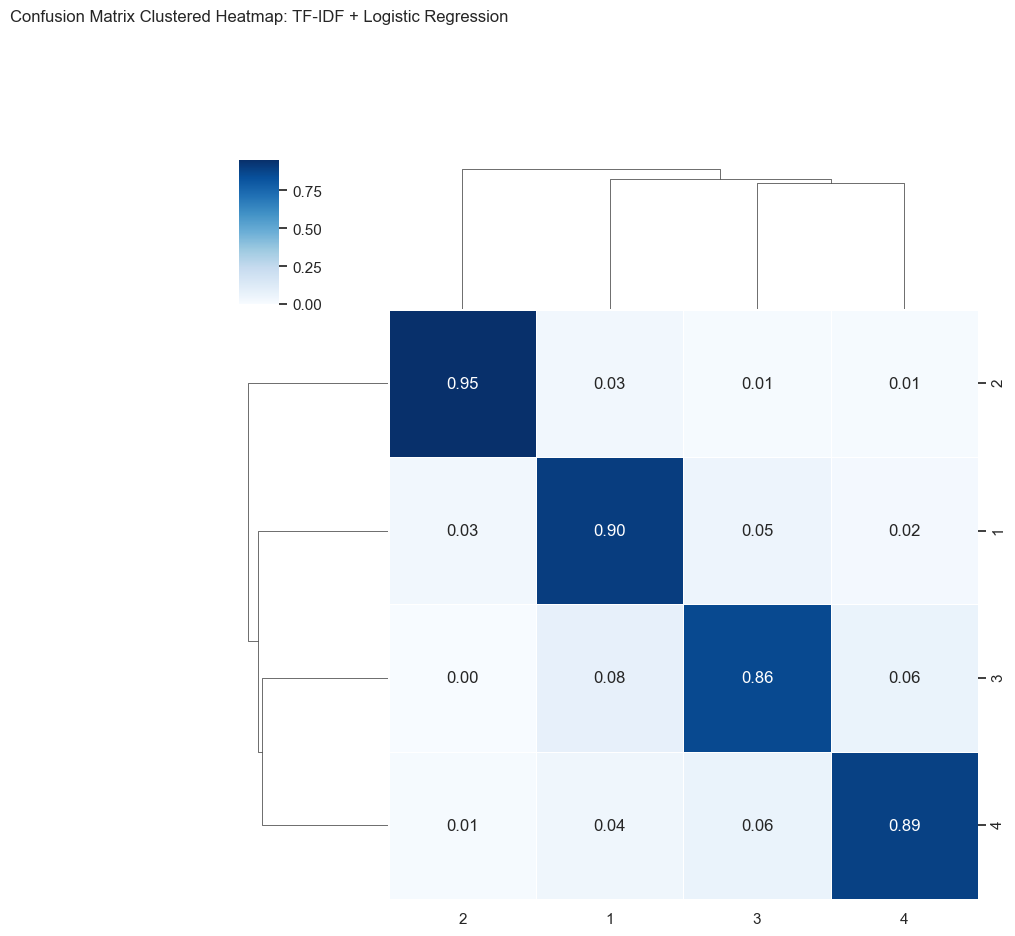

In [64]:
## return confusion matrix

# Choose a combination
combo_name = "TF-IDF + Logistic Regression"
cm = confusion_matrices[combo_name]

labels_sorted = sorted(set(train_labels))

# Normalize rows to sum to 1
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, None]

# Convert to DataFrame for seaborn
cm_df = pd.DataFrame(cm_norm, index=labels_sorted, columns=labels_sorted)

import seaborn as sns
import matplotlib.pyplot as plt

# Clustered heatmap: rows/columns reordered according to hierarchical clustering
sns.set(font_scale=1)
g = sns.clustermap(
    cm_df,
    cmap="Blues",
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    figsize=(8, 8),
    row_cluster=True,
    col_cluster=True
)
plt.title(f"Confusion Matrix Clustered Heatmap: {combo_name}", pad=100)
plt.show()


In [65]:
pipeline = TextClassificationPipeline(stat_sampled_train_texts, stat_sampled_train_labels, sampled_test_texts, sampled_test_labels, 
                                      pretrained_word2vec_model=w2v_model,
                                      pretrained_fasttext_model=fasttext_model)

In [66]:
best_models_df = results_df.sort_values(by="F1-score", ascending=False)

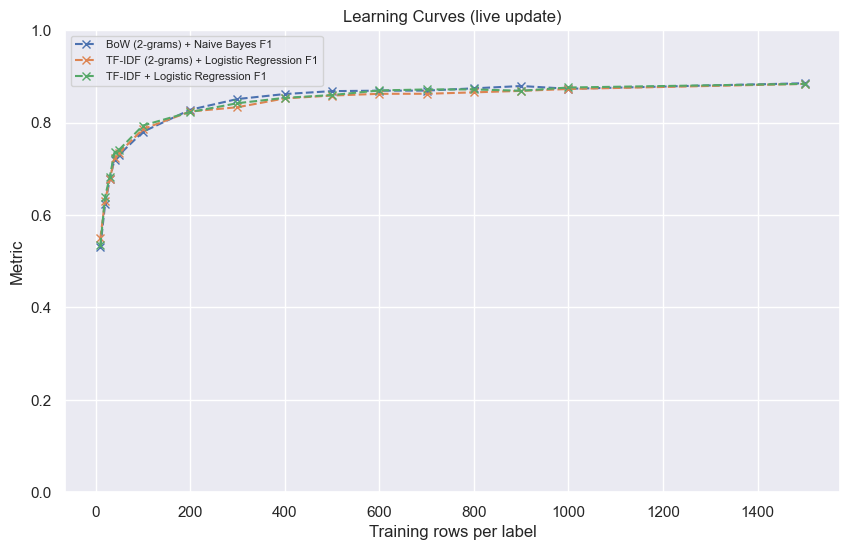

Training sizes: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:12<00:00,  1.30it/s]


In [141]:
learning_results = pipeline.run_learning_curve(
    train_sizes=[10,20,30,40,50,100,200,300,400,500,600,700,800,900,1000,1500],
    plot_live=True,
    #selected_combinations=[
    #    ("TF-IDF", "Logistic Regression"),
     #   ("BoW", "Naive Bayes"),
    #    ("Word2Vec", "Logistic Regression")
    #]
    selected_combinations=[
        best_models_df[["Vectorizer","Model"]].iloc[0],
        best_models_df[["Vectorizer","Model"]].iloc[1],
        best_models_df[["Vectorizer","Model"]].iloc[2],

    ]
)

In [140]:
import pandas as pd

def nested_results_to_df(learning_results):
    """
    Convert nested learning curve results dict to a flat DataFrame.
    """
    all_rows = []
    for combo_key, metrics_list in learning_results.items():
        for metric_entry in metrics_list:
            row = {"Combination": combo_key}
            row.update(metric_entry)  # add TrainSize, Accuracy, F1-score, etc.
            all_rows.append(row)
    df = pd.DataFrame(all_rows)
    return df

# Example usage:
learning_results_df = nested_results_to_df(learning_results)
display(learning_results_df)


,Combination,TrainSize,Accuracy,F1-score
0,BoW (2-grams) + Naive Bayes,10,0.530,0.529981
1,BoW (2-grams) + Naive Bayes,20,0.625,0.623375
2,BoW (2-grams) + Naive Bayes,30,0.679,0.677513
3,BoW (2-grams) + Naive Bayes,40,0.722,0.720183
4,BoW (2-grams) + Naive Bayes,50,0.733,0.730488
5,BoW (2-grams) + Naive Bayes,100,0.782,0.780223
6,BoW (2-grams) + Naive Bayes,200,0.828,0.827895
7,BoW (2-grams) + Naive Bayes,300,0.851,0.851122
8,BoW (2-grams) + Naive Bayes,400,0.862,0.861907
9,BoW (2-grams) + Naive Bayes,500,0.868,0.868260


In [32]:
## at what point are there diminishing returns in training data? 

def find_diminishing_point(sizes, values, threshold=0.001):
    """
    Returns the smallest training size where improvement falls below threshold.

    Parameters
    ----------
    sizes : list of int
        Training sizes used in the learning curve.
    values : list of float
        Metric values (e.g., Accuracy or F1-score) corresponding to each size.
    threshold : float
        Minimum slope considered significant improvement. Default = 0.001.

    Returns
    -------
    cutoff_size : int
        Training size at which the metric improvement falls below the threshold.
    """
    for i in range(1, len(sizes)):
        delta = (values[i] - values[i-1]) / (sizes[i] - sizes[i-1])
        if delta < threshold:
            return sizes[i]
    return sizes[-1]  # If threshold never reached, return max size

combo_key = best_combo
sizes = [d["TrainSize"] for d in learning_results[combo_key]]
accuracy_values = [d["Accuracy"] for d in learning_results[combo_key]]
f1_values = [d["F1-score"] for d in learning_results[combo_key]]

cutoff_acc = find_diminishing_point(sizes, accuracy_values, threshold=0.001)
cutoff_f1 = find_diminishing_point(sizes, f1_values, threshold=0.001)

print(f"{combo_key}: Accuracy starts diminishing at ~{cutoff_acc} rows per label")
print(f"{combo_key}: F1-score starts diminishing at ~{cutoff_f1} rows per label")

TF-IDF + SVM: Accuracy starts diminishing at ~100 rows per label
TF-IDF + SVM: F1-score starts diminishing at ~100 rows per label


## RNN model variant

Epoch 1/5


/Users/robertheld/miniconda3/envs/gensim_env/lib/python3.11/site-packages/keras/src/layers/core/embedding.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3685 - loss: 1.3150
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8575 - loss: 0.5109
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9453 - loss: 0.1864
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9788 - loss: 0.0923
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9894 - loss: 0.0499
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Classification Report:

              precision    recall  f1-score   support

           1       0.84      0.87      0.85       100
           2       0.93      0.93      0.93       100
           3       0.76      0.80      0.78       100
           4       0.84      0.76      0.80       100

    accuracy                           0.84       400
   macro avg       0.84      0.84      0.84       400
weighted avg       0.84      0.84      0.84       400



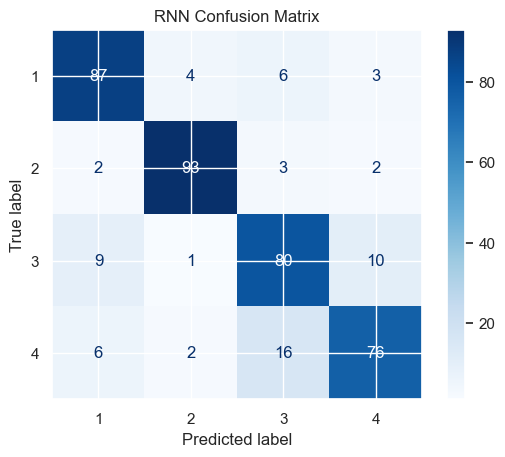

In [34]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ---- Parameters ----
vocab_size = 10000     # maximum number of words in the vocabulary
max_seq_len = 100      # maximum sequence length for padding
embed_dim = 50         # embedding vector size
batch_size = 32
epochs = 5

# ---- Replace these with your actual data ----
# train_texts = [...]
# train_labels = [...]
# test_texts = [...]
# test_labels = [...]

# ---- Tokenization and padding ----
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

X_train_pad = pad_sequences(tokenizer.texts_to_sequences(sampled_train_texts), maxlen=max_seq_len)
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(sampled_test_texts), maxlen=max_seq_len)

y_train = np.array(sampled_train_labels)
y_test = np.array(sampled_test_labels)

num_classes = len(set(y_train))

# ---- RNN model builder ----
def build_rnn_model(vocab_size=vocab_size, input_length=max_seq_len, num_classes=num_classes, embed_dim=embed_dim):
    model = Sequential()
    model.add(Embedding(input_dim=vocab_size, output_dim=embed_dim, input_shape=(input_length,)))
    model.add(LSTM(64))
    model.add(Dense(num_classes, activation='softmax'))  # multi-class output
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

# ---- Wrap in SciKeras classifier ----
rnn_clf = KerasClassifier(
    model=build_rnn_model,
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)

# ---- Train the model ----
rnn_clf.fit(X_train_pad, y_train)

# ---- Predict ----
y_pred = rnn_clf.predict(X_test_pad)

# ---- Evaluation ----
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

labels_sorted = sorted(set(y_test))
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_sorted)
disp.plot(cmap=plt.cm.Blues)
plt.title("RNN Confusion Matrix")
plt.show()


## Repeatability

In [35]:
# Get the instantiated vectorizer and model
best_vec = pipeline.vectorizers[best_row['Vectorizer']]
best_model = pipeline.models[best_row['Model']]

In [37]:
# Step 3: Set number of runs
N_RUNS = 100
print(f"\nRunning repeatability test for {N_RUNS} iterations...")

# Step 4: Store predictions
all_preds = []

for i in tqdm(range(N_RUNS)):
    # Recreate fresh instances (some models may carry fitted state)
    from copy import deepcopy
    vec = deepcopy(best_vec)
    model = deepcopy(best_model)
    
    # Fit + Predict using same train/test split
    clf = Pipeline([
        ("vectorizer", vec),
        ("classifier", model)
    ])
    clf.fit(sampled_train_texts, sampled_train_labels)
    preds = clf.predict(sampled_test_texts)
    
    all_preds.append(preds)

# Convert to numpy array for comparison
all_preds = np.array(all_preds)  # shape: (N_RUNS, n_samples)

# Step 5: Measure repeatability per row
n_samples = all_preds.shape[1]
repeatable_counts = []

for j in range(n_samples):
    sample_preds = all_preds[:, j]
    most_common_label, count = Counter(sample_preds).most_common(1)[0]
    repeatable_counts.append(count)

# Step 6: Compute repeatability stats
perfectly_repeatable = sum(count == N_RUNS for count in repeatable_counts)
percent_repeatable = perfectly_repeatable / n_samples * 100
percent_variable = 100 - percent_repeatable

print("\n Repeatability results:")
print(f"Total test samples: {n_samples}")
print(f"Perfectly repeatable: {perfectly_repeatable} ({percent_repeatable:.2f}%)")
print(f"Variable across runs: {n_samples - perfectly_repeatable} ({percent_variable:.2f}%)")

# Step 7 (optional): Inspect non-repeatable rows
variable_indices = [i for i, count in enumerate(repeatable_counts) if count < N_RUNS]
if variable_indices:
    print("\n Non-repeatable samples (first few):")
    for idx in variable_indices[:10]:
        preds_for_row = Counter(all_preds[:, idx])
        print(f"Row {idx}: {preds_for_row}")


Running repeatability test for 100 iterations...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [03:44<00:00,  2.24s/it]


🔁 Repeatability results:
Total test samples: 400
Perfectly repeatable: 400 (100.00%)
Variable across runs: 0 (0.00%)


## LLM variant

In [38]:
## start chatbot 

# pip install striprtf

from striprtf.striprtf import rtf_to_text

# Path to your RTF file for API key:
rtf_file_path = "/Users/"

with open(rtf_file_path, "r", encoding="utf-8") as f:
    rtf_content = f.read()

# Convert RTF to plain text
plain_text = rtf_to_text(rtf_content).strip()

# Assuming the API key is the only content
api_key = plain_text
print("API Key loaded successfully (hidden here).")

# Read RTF content
with open(rtf_file_path, "r", encoding="utf-8") as f:
    rtf_content = f.read()

# Convert RTF to plain text
plain_text = rtf_to_text(rtf_content).strip()

if plain_text:
    # Set environment variable
    os.environ["OPENAI_API_KEY"] = plain_text
    print("OPENAI_API_KEY set as environment variable.")
else:
    raise ValueError("No API key found in the RTF file.")

del plain_text, api_key

API Key loaded successfully (hidden here).
OPENAI_API_KEY set as environment variable.


In [142]:
#check modles behind "gpt-4" and stay in control of which model is in use
#from openai import OpenAI
#client = OpenAI()
#models = client.models.list()
#print([m.id for m in models.data if "gpt-4" in m.id])

['gpt-4-0613', 'gpt-4', 'gpt-4-1106-preview', 'gpt-4-0125-preview', 'gpt-4-turbo-preview', 'gpt-4-turbo', 'gpt-4-turbo-2024-04-09', 'gpt-4o', 'gpt-4o-2024-05-13', 'gpt-4o-mini-2024-07-18', 'gpt-4o-mini', 'gpt-4o-2024-08-06', 'chatgpt-4o-latest', 'gpt-4o-realtime-preview-2024-10-01', 'gpt-4o-audio-preview-2024-10-01', 'gpt-4o-audio-preview', 'gpt-4o-realtime-preview', 'gpt-4o-realtime-preview-2024-12-17', 'gpt-4o-audio-preview-2024-12-17', 'gpt-4o-mini-realtime-preview-2024-12-17', 'gpt-4o-mini-audio-preview-2024-12-17', 'gpt-4o-mini-realtime-preview', 'gpt-4o-mini-audio-preview', 'gpt-4o-2024-11-20', 'gpt-4o-search-preview-2025-03-11', 'gpt-4o-search-preview', 'gpt-4o-mini-search-preview-2025-03-11', 'gpt-4o-mini-search-preview', 'gpt-4o-transcribe', 'gpt-4o-mini-transcribe', 'gpt-4o-mini-tts', 'gpt-4.1-2025-04-14', 'gpt-4.1', 'gpt-4.1-mini-2025-04-14', 'gpt-4.1-mini', 'gpt-4.1-nano-2025-04-14', 'gpt-4.1-nano', 'gpt-4o-realtime-preview-2025-06-03', 'gpt-4o-audio-preview-2025-06-03', 'g

In [39]:
#Create ChatGPTClassifier that estimates costs, requires user input to continue and has throttle control


class ChatGPTClassifier(BaseEstimator, ClassifierMixin):
    """
    Unified ChatGPT classifier:
      - Zero-shot if fit() is called without data.
      - Few-shot if fit(X, y) is provided.
      - Automatically handles numeric labels by prompting GPT with human-readable labels
        (via label_map if provided) and converting GPT outputs back to the original label type.
      - Supports test_user_input mode for simulating confirmation and predictions safely.
    """

    def __init__(self, api_key=None, categories=None, label_map=None,
                 max_calls_per_minute=20, dry_run=True, test_user_input=False,
                throttle_enabled=True):
        """
        Parameters
        ----------
        api_key : str or None
            OpenAI API key (optional if dry_run=True)
        categories : list
            Allowed class labels (either numeric or strings), e.g. [1,2,3,4] or ["A","B"]
        label_map : dict (optional)
            Mapping from category -> human readable label for GPT prompts.
            Example: {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
        max_calls_per_minute : int
            Throttle; default 20 calls/minute.
        dry_run : bool
            If True, returns simulated predictions for testing (no API calls).
        test_user_input : bool
            If True, forces cost confirmation and user input testing
            even when dry_run=True or API key is placeholder.
        """
        if categories is None or len(categories) == 0:
            raise ValueError("You must provide a list of categories.")

        self.api_key = api_key
        self.categories = list(categories)
        self.label_map = label_map or {}
        self.inv_label_map = {v.lower(): k for k, v in self.label_map.items()} if self.label_map else {}

        self.max_calls_per_minute = max_calls_per_minute
        self.last_call_time = 0.0
        self.call_interval = 60.0 / max_calls_per_minute
        self.dry_run = dry_run
        self.test_user_input = test_user_input
        self.throttle_enabled = throttle_enabled   # ← STORE FLAG

        # Detect whether categories are numeric
        self.numeric_labels = all(isinstance(c, (int, np.integer)) for c in self.categories)

        # Few-shot example storage
        self.few_shot_examples = []
        self.zero_shot_mode = True

        # Human-readable labels for GPT prompts
        if self.label_map:
            self.readable_labels = [self.label_map.get(c, str(c)) for c in self.categories]
        else:
            self.readable_labels = [str(c) for c in self.categories]

        self.readable_labels_lower = [rl.lower() for rl in self.readable_labels]

    # ---------------- Utility helpers ----------------

    def _is_placeholder_key(self):
        """Detect whether the API key looks like a real OpenAI key."""
        if not self.api_key:
            return True
        return not bool(re.match(r"^sk-[A-Za-z0-9]{20,}$", self.api_key))

    import tiktoken

    def _estimate_cost(self, X_or_n, avg_completion_tokens=50,
                       avg_example_tokens=150, rate_in=0.01, rate_out=0.03,
                       model="gpt-4"): #family of models, can be inconsistent over time
                       #model="gpt-4.1"): #hard-code which model
                       #model="gpt-4-0613"): #used in most analyses
        """
        Estimate GPT cost in USD.
        Handles either:
          - a list of test samples (X), or
          - an integer (n_samples)
        """
    
        # --- Determine number of samples ---
        if isinstance(X_or_n, int):
            n_samples = X_or_n
        elif hasattr(X_or_n, "__len__"):
            n_samples = len(X_or_n)
        else:
            raise ValueError("Expected list of samples or int for n_samples")
    
        # --- Estimate token usage ---
        few_shot_count = len(getattr(self, "few_shot_examples", []))
        avg_prompt_tokens = 250 + (few_shot_count * avg_example_tokens)
        avg_completion_tokens = avg_completion_tokens
    
        # --- Compute cost ---
        cost_per_sample = ((avg_prompt_tokens / 1000) * rate_in) + ((avg_completion_tokens / 1000) * rate_out)
        total_cost = n_samples * cost_per_sample
    
        # --- Return detailed breakdown ---
        return {
            "n_samples": n_samples,
            "few_shot_examples": few_shot_count,
            "avg_prompt_tokens": avg_prompt_tokens,
            "avg_completion_tokens": avg_completion_tokens,
            "cost_per_sample": cost_per_sample,
            "total_cost": total_cost,
            "rate_in": rate_in,
            "rate_out": rate_out,
            "model": model,
            "mode": "few-shot" if few_shot_count else "zero-shot",
        }




    def _confirm_cost(self, X):
        """
        Ask user for confirmation of estimated API cost.
        Works for either list of texts or n_samples.
        """
        if not self.test_user_input:
            if self.dry_run or self._is_placeholder_key():
                return True  # skip normally
    
        breakdown = self._estimate_cost(X)
        mode = breakdown["mode"]
    
        print("\n--- API Cost Estimate (GPT-4) ---")
        print(f"Mode: {mode}")
        print(f"Samples: {breakdown['n_samples']}")
        print(f"Few-shot examples: {breakdown['few_shot_examples']}")
        print(f"Prompt tokens per request: ~{breakdown['avg_prompt_tokens']}")
        print(f"Completion tokens per request: ~{breakdown['avg_completion_tokens']}")
        print(f"Cost per sample: ${breakdown['cost_per_sample']:.5f}")
        print(f"Total estimated cost: ${breakdown['total_cost']:.4f}\n")
    
        user_input = input("Proceed with API calls? Type 'YES' to confirm: ").strip()
        if user_input.upper() != "YES":
            print("Denied by user.")
            return False
        return True




    def _throttle(self):
        """Throttle to respect a calls-per-minute limit.
        Also gives user time to realise mistakes before they become too costly"""
        if not self.throttle_enabled:
            # Skip throttling entirely for testing
            return
        elapsed = time.time() - self.last_call_time
        if elapsed < self.call_interval:
            time.sleep(self.call_interval - elapsed)
        self.last_call_time = time.time()

    # ---------------- Few-shot / prompt construction ----------------

    def fit(self, X=None, y=None):
        """If X,y provided, store examples for few-shot; otherwise zero-shot."""
        if X is not None and y is not None:
            if len(X) != len(y):
                raise ValueError("X and y must be the same length.")
            self.few_shot_examples = list(zip(X, y))
            self.zero_shot_mode = False
        else:
            self.few_shot_examples = []
            self.zero_shot_mode = True
        return self

    def _generate_prompt(self, text):
        """Generate GPT prompt including few-shot examples if applicable."""
        categories_str = ", ".join(self.readable_labels)

        prompt = (
            "You are a precise text classification system.\n"
            f"Classify the following text into exactly one of these categories: {categories_str}.\n\n"
            "Important: answer with exactly one of the allowed category names (no explanation, no punctuation).\n\n"
        )

        if not self.zero_shot_mode and self.few_shot_examples:
            prompt += "Here are some examples:\n"
            for ex_text, ex_label in self.few_shot_examples:
                if ex_label in self.label_map:
                    ex_label_str = self.label_map[ex_label]
                else:
                    ex_label_str = str(ex_label)
                prompt += f"Text: {ex_text}\nLabel: {ex_label_str}\n\n"

        prompt += f"Text: {text}\nLabel:"
        return prompt

    # ---------------- Mapping ----------------

    def _map_gpt_output_to_category(self, label_raw):
        """Map GPT textual output back to original category type."""
        label_clean = label_raw.strip().lower()

        if label_clean in self.readable_labels_lower:
            idx = self.readable_labels_lower.index(label_clean)
            return self.categories[idx]

        if self.inv_label_map and label_clean in self.inv_label_map:
            return self.inv_label_map[label_clean]

        closest = get_close_matches(label_clean, self.readable_labels_lower, n=1)
        if closest:
            idx = self.readable_labels_lower.index(closest[0])
            return self.categories[idx]

        if self.numeric_labels and label_clean.isdigit():
            val = int(label_clean)
            if val in self.categories:
                return val

        return self.categories[0]  # fallback

    # ---------------- Prediction ----------------

    def predict(self, X):
        """Predict labels for X, with throttling and automatic retry on 429 errors."""
        import openai
        preds = []
        n_samples = len(X)
    
        # Confirm cost first
        if not self._confirm_cost(X):
            return [None] * len(X)
    
        if not self.dry_run and self.api_key:
            openai.api_key = self.api_key
    
        for i, text in enumerate(X):
            self._throttle()
            prompt = self._generate_prompt(text)
    
            # --- API Call with retry logic ---
            label_raw = None
            for attempt in range(6):  # retry up to 6 times
                try:
                    if not self.dry_run:
                        response = openai.chat.completions.create(
                            model="gpt-4",   
                            #model="gpt-4o-mini", #  cheaper + higher limits
                            messages=[{"role": "user", "content": prompt}],
                            temperature=0
                        )
                        label_raw = response.choices[0].message.content
                    else:
                        # Simulated response
                        label_raw = np.random.choice(self.readable_labels)
                    break  # success → exit retry loop
    
                except openai.RateLimitError:
                    wait = min(10, (attempt + 1) * 2)
                    print(f"Rate limit hit, waiting {wait}s before retrying...")
                    time.sleep(wait)
    
                except Exception as e:
                    print(f"API error: {e}, retrying...")
                    time.sleep(3)
    
            if label_raw is None:
                print(f"Failed after retries, using fallback label.")
                label_raw = self.readable_labels[0]
    
            category = self._map_gpt_output_to_category(label_raw)
            preds.append(category)
    
            # Periodically save progress
            if (i + 1) % 20 == 0 or (i + 1) == len(X):
                pd.DataFrame({
                    "Text": X[:i + 1],
                    "Pred": preds
                }).to_csv("partial_preds.csv", index=False)
                print(f"Saved {i + 1} predictions to partial_preds.csv")
    
            # Optional progress logging
            if (i + 1) % 10 == 0:
                print(f"Processed {i + 1}/{n_samples} samples")
    
        return preds

In [40]:
## Create and evaluator that demonstrates ChatGPTClassifier performance

# with cache option for saving on costs with multiple iterations. do not use for repeatability testing.

class ChatGPTClassifierWithEval(ChatGPTClassifier):
    """
    Extends ChatGPTClassifier with an evaluation helper.
    """
    def evaluate(self, X_test, y_test, model_name="ChatGPT", use_cache=False, temperature=0.0):
        from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    
        preds = self.predict(X_test) if not (use_cache and hasattr(self, "_cached_predictions")) else self._cached_predictions
    
        # Metrics
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, average="weighted", zero_division=0)
        rec = recall_score(y_test, preds, average="weighted", zero_division=0)
        f1 = f1_score(y_test, preds, average="weighted", zero_division=0)
    
        per_text_df = pd.DataFrame({
            "Text": X_test,
            "True_Label": y_test,
            "Predicted_Label": preds
        })
    
        metrics_df = pd.DataFrame([{
            "Model": model_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1": f1
        }])
    
        print(f"{model_name} - Accuracy: {acc:.3f}, F1: {f1:.3f}")
        return per_text_df, metrics_df

### Zero Shot: no semantic labels, no training

In [96]:
#double check that the len = 100
print(len(sampled_test_texts))
print(len(sampled_test_labels))

100

In [100]:
#no labels llm

# --- Initialize zero-shot GPT classifier ---
gpt_zero_shot = ChatGPTClassifierWithEval(
    api_key=os.environ["OPENAI_API_KEY"],
    categories=categories,
    #label_map=label_map, #no labels used
    dry_run=False,  # set False for real API calls
    throttle_enabled = True, #set to False for testing to remove throttle for faster iterations
    max_calls_per_minute=60,  #no training data, set higher than few shot
    test_user_input=True #set to True to have estimate of cost before api call
)

# zero-shot mode
gpt_zero_shot.fit()  # no data -> zero-shot


# Evaluate
per_text_df_zs_nl, metrics_df_zs_nl = gpt_zero_shot.evaluate(sampled_test_texts, sampled_test_labels, model_name="ChatGPT (Zero-shot) No Labels")


--- API Cost Estimate (GPT-4) ---
Mode: zero-shot
Samples: 100
Few-shot examples: 0
Prompt tokens per request: ~250
Completion tokens per request: ~50
Cost per sample: $0.00400
Total estimated cost: $0.4000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Zero-shot) No Labels - Accuracy: 0.210, F1: 0.173


In [101]:
metrics_df_zs_nl

,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Zero-shot) No Labels,0.21,0.260379,0.21,0.172991


### Zero Shot: no training data (with semantic labels)

In [102]:
## Zero shot: no training data (no examples in prompt)
#export interim results in partial_preds.csv to save progress in case of disruption

partial_file = "partial_preds.csv"

# Initialize file (overwrite if exists)
if os.path.exists(partial_file):
    os.remove(partial_file)

preds = []

# --- Numeric categories and human-readable labels ---
categories = [1, 2, 3, 4]
label_map = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}

# --- Initialize zero-shot GPT classifier ---
gpt_zero_shot = ChatGPTClassifierWithEval(
    api_key=os.environ["OPENAI_API_KEY"],
    categories=categories,
    label_map=label_map,
    dry_run=False,  # set False for real API calls
    throttle_enabled = True, #set to False for testing to remove throttle for faster iterations
    max_calls_per_minute=60,  #no training data, set higher than few shot
    test_user_input=True #set to True to have estimate of cost before api call
)

# zero-shot mode
gpt_zero_shot.fit()  # no data = zero-shot


# Evaluate
per_text_df_zs, metrics_df_zs = gpt_zero_shot.evaluate(sampled_test_texts, sampled_test_labels, model_name="ChatGPT (Zero-shot)")

metrics_df_zs       # numeric metrics


--- API Cost Estimate (GPT-4) ---
Mode: zero-shot
Samples: 100
Few-shot examples: 0
Prompt tokens per request: ~250
Completion tokens per request: ~50
Cost per sample: $0.00400
Total estimated cost: $0.4000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Zero-shot) - Accuracy: 0.860, F1: 0.851


,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Zero-shot),0.86,0.890756,0.86,0.850858


In [103]:
metrics_df_zs

,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Zero-shot),0.86,0.890756,0.86,0.850858


### Few Shot: one row

In [105]:
#few shot (determined by sample limits)

# Initialize classifier
clf = ChatGPTClassifierWithEval(
    api_key=os.getenv("OPENAI_API_KEY"),   # dry_run=True
    categories=[1,2,3,4],
    label_map={1:"World", 2:"Sports", 3:"Business", 4:"Sci/Tech"},
    dry_run=False,
    throttle_enabled=True,
    max_calls_per_minute=60,  
    test_user_input=True #set to True to have estimate of cost before api call

)

# Few-shot fit
clf.fit(os_sampled_train_texts, os_sampled_train_labels)

# Evaluate on test set
per_text_df_os, metrics_df_os = clf.evaluate(sampled_test_texts, sampled_test_labels, model_name="ChatGPT (One-shot)")

metrics_df_os


--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 4
Prompt tokens per request: ~850
Completion tokens per request: ~50
Cost per sample: $0.01000
Total estimated cost: $1.0000



Proceed with API calls? Type 'YES' to confirm:  no


Denied by user.


ValueError: Classification metrics can't handle a mix of multiclass and unknown targets

### Few Shot: 5 Rows

In [109]:
#few shot (determined by sample limits)

# Initialize classifier
clf = ChatGPTClassifierWithEval(
    api_key=os.getenv("OPENAI_API_KEY"),   # dry_run=True
    categories=[1,2,3,4],
    label_map={1:"World", 2:"Sports", 3:"Business", 4:"Sci/Tech"},
    dry_run=False,
    throttle_enabled=True,
    max_calls_per_minute=10, #set lower given amount of training data being passed 
    test_user_input=True #set to True to have estimate of cost before api call

)

# Few-shot fit
clf.fit(fs_sampled_train_texts, fs_sampled_train_labels)

# Evaluate on test set
per_text_df_fs5, metrics_df_fs5 = clf.evaluate(sampled_test_texts, sampled_test_labels, model_name="ChatGPT (Few-shot: 5)")

metrics_df_fs5


--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 20
Prompt tokens per request: ~3250
Completion tokens per request: ~50
Cost per sample: $0.03400
Total estimated cost: $3.4000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot: 5) - Accuracy: 0.900, F1: 0.895


,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Few-shot: 5),0.9,0.916763,0.9,0.895257


### Few Shot: 10 rows

In [107]:
# few shot (determined by sample limits)

# Initialize classifier
clf = ChatGPTClassifierWithEval(
    api_key=os.getenv("OPENAI_API_KEY"),   # dry_run=True
    categories=[1,2,3,4],
    label_map={1:"World", 2:"Sports", 3:"Business", 4:"Sci/Tech"},
    dry_run=False,
    throttle_enabled=True,
    max_calls_per_minute=10,  
    test_user_input=True #set to True to have estimate of cost before api call

)

# Few-shot fit
clf.fit(llm_sampled_train_texts, llm_sampled_train_labels)

# Evaluate on test set
per_text_df_fs10, metrics_df_fs10 = clf.evaluate(sampled_test_texts, sampled_test_labels, model_name="ChatGPT (Few-shot: 10)")

metrics_df_fs10


--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 40
Prompt tokens per request: ~6250
Completion tokens per request: ~50
Cost per sample: $0.06400
Total estimated cost: $6.4000



Proceed with API calls? Type 'YES' to confirm:  yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot: 10) - Accuracy: 0.870, F1: 0.859


,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Few-shot: 10),0.87,0.895161,0.87,0.858553


In [113]:
llm_results = pd.concat([metrics_df_zs_nl,metrics_df_zs,#metrics_df_os,
                         metrics_df_fs5,metrics_df_fs10])

In [114]:
llm_results

,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Zero-shot) No Labels,0.21,0.260379,0.21,0.172991
0,ChatGPT (Zero-shot),0.86,0.890756,0.86,0.850858
0,ChatGPT (Few-shot: 5),0.90,0.916763,0.90,0.895257
0,ChatGPT (Few-shot: 10),0.87,0.895161,0.87,0.858553


In [87]:
# concat chatbot output: zero shot and few shot

#pd.concat([metrics_df,metrics_df_fs10])

,Model,Accuracy,Precision,Recall,F1
0,ChatGPT (Zero-shot),0.200,0.186480,0.200,0.191784
0,ChatGPT (Few-shot: 10),0.275,0.274123,0.275,0.257040


### Chatbot Repeatability

In [108]:
def test_chatgpt_repeatability(
    clf,
    train_texts,
    train_labels,
    test_texts,
    test_labels,
    label_map,
    n_iterations=10,
    delay_minutes=0,
    temperature=0.0,
    cache_enabled=True
):
    """
    Tests repeatability of ChatGPT classification results across multiple runs.
    Returns:
        repeat_text_df  -> per-text repeatability DataFrame
        repeat_metrics_df -> per-run metrics summary DataFrame
    """

    print(f"\n=== ChatGPT Repeatability Test ===")
    print(f"Model temperature: {temperature}")
    print(f"Number of iterations: {n_iterations}")
    print(f"Delay between iterations: {delay_minutes} minute(s)")
    print(f"Caching enabled: {cache_enabled}")

    # Step 1. Train few-shot examples (cached in clf)
    clf.fit(os_sampled_train_texts, os_sampled_train_labels)
    clf.temperature = temperature
    clf.use_cache = cache_enabled

    all_preds = []
    all_metrics = []

    # Step 2. Run classification n times
    for i in range(n_iterations):
        print(f"\n--- Iteration {i+1}/{n_iterations} ---")

        # Evaluate model (returns per-text + metrics)
        per_text_df, metrics_df = clf.evaluate(
            test_texts, test_labels,
            model_name=f"ChatGPT (Few-shot Run {i+1})",
            use_cache=cache_enabled,
            temperature=temperature
        )

        # Get predictions list
        preds = per_text_df["Predicted_Label"].tolist()
        all_preds.append(preds)
        all_metrics.append(metrics_df.assign(Run=i+1))

        print(f"Iteration {i+1} complete — accuracy: {metrics_df['Accuracy'].iloc[0]:.3f}")

        # Save partial results (optional safety)
        per_text_df.to_csv(f"repeat_run_{i+1}.csv", index=False)
        metrics_df.to_csv(f"repeat_metrics_{i+1}.csv", index=False)

        # Sleep between runs (optional)
        if i < n_iterations - 1 and delay_minutes > 0:
            sleep_seconds = delay_minutes * 60
            print(f"Sleeping {sleep_seconds} seconds before next iteration...")
            time.sleep(sleep_seconds)

    # Step 3. Measure consistency
    print("\n=== Repeatability Analysis ===")
    df_repeats = pd.DataFrame(all_preds).T
    df_repeats.columns = [f"Run_{i+1}" for i in range(n_iterations)]
    df_repeats["True_Label"] = test_labels

    # Compute per-row consistency
    consistent_counts = []
    for _, row in df_repeats.iterrows():
        pred_values = row[:-1].tolist()
        most_common_label, count = Counter(pred_values).most_common(1)[0]
        consistency = count / n_iterations
        consistent_counts.append(consistency)

    df_repeats["Consistency"] = consistent_counts
    overall_repeatability = sum(c == 1.0 for c in consistent_counts) / len(consistent_counts)

    print(f"\nRepeatability (100% identical classifications): {overall_repeatability:.2%}")
    print(f"Average per-row consistency: {sum(consistent_counts)/len(consistent_counts):.2%}")

    # Merge metrics across runs
    repeat_metrics_df = pd.concat(all_metrics, ignore_index=True)

    return df_repeats, repeat_metrics_df

In [111]:
## perform repeatability test

# Initialize classifier
clf = ChatGPTClassifierWithEval(
    api_key=os.getenv("OPENAI_API_KEY"),
    categories=[1, 2, 3, 4],
    label_map={1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"},
    dry_run=False,
    max_calls_per_minute=10,  
    throttle_enabled=True,
    test_user_input=True,
)

# Run repeatability test
#repeat_text_df, repeat_metrics_df = test_chatgpt_repeatability(
repeat_text_df, repeat_metrics_df = test_chatgpt_repeatability(
    clf=clf,
    train_texts=os_sampled_train_texts,
    train_labels=os_sampled_train_labels,
    test_texts=sampled_test_texts,
    test_labels=sampled_test_labels,
    label_map={1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"},
    n_iterations=5,
    delay_minutes=2,   # can later set to 30
    temperature=0.0,
    cache_enabled=False #will also store answers
)


# Save or inspect results
#repeat_results.to_csv("chatgpt_repeatability_results.csv", index=False)
#print("\nSaved repeatability results to chatgpt_repeatability_results.csv")


=== ChatGPT Repeatability Test ===
Model temperature: 0.0
Number of iterations: 5
Delay between iterations: 2 minute(s)
Caching enabled: False

--- Iteration 1/5 ---

--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 4
Prompt tokens per request: ~850
Completion tokens per request: ~50
Cost per sample: $0.01000
Total estimated cost: $1.0000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot Run 1) - Accuracy: 0.900, F1: 0.897
Iteration 1 complete — accuracy: 0.900
Sleeping 120 seconds before next iteration...

--- Iteration 2/5 ---

--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 4
Prompt tokens per request: ~850
Completion tokens per request: ~50
Cost per sample: $0.01000
Total estimated cost: $1.0000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot Run 2) - Accuracy: 0.870, F1: 0.862
Iteration 2 complete — accuracy: 0.870
Sleeping 120 seconds before next iteration...

--- Iteration 3/5 ---

--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 4
Prompt tokens per request: ~850
Completion tokens per request: ~50
Cost per sample: $0.01000
Total estimated cost: $1.0000



Proceed with API calls? Type 'YES' to confirm:  yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot Run 3) - Accuracy: 0.900, F1: 0.897
Iteration 3 complete — accuracy: 0.900
Sleeping 120 seconds before next iteration...

--- Iteration 4/5 ---

--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 4
Prompt tokens per request: ~850
Completion tokens per request: ~50
Cost per sample: $0.01000
Total estimated cost: $1.0000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot Run 4) - Accuracy: 0.880, F1: 0.874
Iteration 4 complete — accuracy: 0.880
Sleeping 120 seconds before next iteration...

--- Iteration 5/5 ---

--- API Cost Estimate (GPT-4) ---
Mode: few-shot
Samples: 100
Few-shot examples: 4
Prompt tokens per request: ~850
Completion tokens per request: ~50
Cost per sample: $0.01000
Total estimated cost: $1.0000



Proceed with API calls? Type 'YES' to confirm:  Yes


Processed 10/100 samples
Saved 20 predictions to partial_preds.csv
Processed 20/100 samples
Processed 30/100 samples
Saved 40 predictions to partial_preds.csv
Processed 40/100 samples
Processed 50/100 samples
Saved 60 predictions to partial_preds.csv
Processed 60/100 samples
Processed 70/100 samples
Saved 80 predictions to partial_preds.csv
Processed 80/100 samples
Processed 90/100 samples
Saved 100 predictions to partial_preds.csv
Processed 100/100 samples
ChatGPT (Few-shot Run 5) - Accuracy: 0.900, F1: 0.895
Iteration 5 complete — accuracy: 0.900

=== Repeatability Analysis ===

Repeatability (100% identical classifications): 95.00%
Average per-row consistency: 98.60%

Saved repeatability results to chatgpt_repeatability_results.csv


In [112]:
repeat_metrics_df

,Model,Accuracy,Precision,Recall,F1,Run
0,ChatGPT (Few-shot Run 1),0.90,0.915771,0.90,0.897436,1
1,ChatGPT (Few-shot Run 2),0.87,0.894397,0.87,0.862236,2
2,ChatGPT (Few-shot Run 3),0.90,0.914286,0.90,0.896978,3
3,ChatGPT (Few-shot Run 4),0.88,0.901786,0.88,0.874441,4
4,ChatGPT (Few-shot Run 5),0.90,0.916763,0.90,0.895257,5


In [230]:
repeat_text_df["Consistency"].value_counts()

Consistency
1.0    99
0.6     1
Name: count, dtype: int64

## Ensemble of Classifiers + LLM Boosting

In [121]:
## run statistical class methods on larger testing sample of dataset

# Initialize pipeline (example)
pipeline = TextClassificationPipeline(
    #train_texts, train_labels, test_texts, test_labels, 
    stat_sampled_train_texts, stat_sampled_train_labels, sampled_test_texts_n1000, sampled_test_labels_n1000, 
    pretrained_word2vec_model=w2v_model,
    pretrained_fasttext_model=fasttext_model
)

# Run experiments
results_df, mistakes_records, fp_fn_matrix_df, confusion_matrices = pipeline.run_experiments()

results_df = pd.DataFrame(results_df)
fp_fn_matrix_df = pd.DataFrame(fp_fn_matrix_df)

results_df.sort_values(by="F1-score",ascending=False)


=== Label distribution in training data ===
3    3000
4    3000
2    3000
1    3000



Running experiments: 100%|██████████████████████████████████████████| 28/28 [03:30<00:00,  7.52s/it]


,Vectorizer,Model,Accuracy,Precision,Recall,F1-score,Misclassifications,Error Rate,Runtime (s)
9,TF-IDF,SVM,0.900,0.900477,0.900,0.900144,100,0.100,19.791598
5,BoW (2-grams),Naive Bayes,0.899,0.900240,0.899,0.899343,101,0.101,0.476702
12,TF-IDF (2-grams),SVM,0.898,0.898409,0.898,0.898125,102,0.102,37.683303
1,BoW,Naive Bayes,0.894,0.895181,0.894,0.894304,106,0.106,0.176543
8,TF-IDF,Logistic Regression,0.893,0.893394,0.893,0.893132,107,0.107,1.259669
11,TF-IDF (2-grams),Logistic Regression,0.893,0.893237,0.893,0.892990,107,0.107,4.086233
2,BoW,SVM,0.891,0.891846,0.891,0.891279,109,0.109,13.481540
6,BoW (2-grams),SVM,0.887,0.887313,0.887,0.887069,113,0.113,31.639737
4,BoW (2-grams),Logistic Regression,0.883,0.884173,0.883,0.883294,117,0.117,2.917481
7,BoW (2-grams),Random Forest,0.879,0.878926,0.879,0.878417,121,0.121,14.951970


In [122]:
##best vec + method combination

# Assuming results_df is returned from run_experiments
best_row = pd.DataFrame(results_df).sort_values(by=["F1-score", "Accuracy"], ascending=[False, False]).iloc[0]
best_combo = f"{best_row['Vectorizer']} + {best_row['Model']}"
print("Best combination:", best_combo)

Best combination: TF-IDF + SVM


In [123]:
#probability stacking to pass variables for boosting

def ensemble_stacking_classifier_proba(pipeline, results_df, top_n=5, use_cv_meta=True):
    """
    Probability-based stacking ensemble using top-N performing (vectorizer + model) combinations.
    Meta-classifier: Logistic Regression.
    
    Returns:
        results: dict with metrics
        preds_df: DataFrame with stacked predictions and max probability
        meta_data: dict with meta-features, meta classifier, classes, etc.
    """
    print(f"\n=== Running Probability-Based Stacking Ensemble (Top {top_n} models) ===")

    # --- Select top-N models ---
    top_combos = pd.DataFrame(results_df).sort_values(by="F1-score", ascending=False).head(top_n)
    print(f"Top {top_n} combinations selected:\n{top_combos[['Vectorizer', 'Model', 'F1-score']]}")

    base_train_probs = []
    base_test_probs = []
    model_names = []
    classes = np.unique(pipeline.train_labels)

    for _, row in top_combos.iterrows():
        vec_name = row["Vectorizer"]
        model_name = row["Model"]
        combo_name = f"{vec_name} + {model_name}"

        vectorizer = pipeline.vectorizers.get(vec_name)
        model = pipeline.models.get(model_name)
        if vectorizer is None or model is None:
            print(f"Skipping missing combo: {combo_name}")
            continue

        clf = SkPipeline([("vectorizer", vectorizer), ("classifier", model)])
        print(f"Training base model: {combo_name}")

        if hasattr(model, "predict_proba"):
            if use_cv_meta:
                skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
                oof_probs = cross_val_predict(clf, pipeline.train_texts, pipeline.train_labels,
                                             cv=skf, method="predict_proba")
            else:
                clf.fit(pipeline.train_texts, pipeline.train_labels)
                oof_probs = clf.predict_proba(pipeline.train_texts)

            # Fit full model and predict test
            clf.fit(pipeline.train_texts, pipeline.train_labels)
            test_probs = clf.predict_proba(pipeline.test_texts)

        else:
            print(f"{combo_name} does not support predict_proba — using hard predictions.")
            if use_cv_meta:
                skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
                oof_preds = cross_val_predict(clf, pipeline.train_texts, pipeline.train_labels,
                                              cv=skf, method="predict")
            else:
                clf.fit(pipeline.train_texts, pipeline.train_labels)
                oof_preds = clf.predict(pipeline.train_texts)

            clf.fit(pipeline.train_texts, pipeline.train_labels)
            test_preds = clf.predict(pipeline.test_texts)

            # Convert to one-hot probabilities
            oof_probs = np.zeros((len(oof_preds), len(classes)))
            test_probs = np.zeros((len(test_preds), len(classes)))
            for i, cls in enumerate(classes):
                oof_probs[:, i] = (oof_preds == cls).astype(float)
                test_probs[:, i] = (test_preds == cls).astype(float)

        base_train_probs.append(oof_probs)
        base_test_probs.append(test_probs)
        model_names.append(combo_name)

    # --- Combine all base model probabilities ---
    X_meta_train = np.hstack(base_train_probs)
    X_meta_test = np.hstack(base_test_probs)
    y_meta_train = np.array(pipeline.train_labels)
    y_meta_test = np.array(pipeline.test_labels)

    print(f"\nMeta-feature matrix shape: {X_meta_train.shape}")

    # --- Train meta-classifier ---
    meta_clf = LogisticRegression(max_iter=1000, random_state=42)
    meta_clf.fit(X_meta_train, y_meta_train)

    # --- Predict on test set ---
    meta_preds = meta_clf.predict(X_meta_test)
    meta_probs = meta_clf.predict_proba(X_meta_test)

    preds_df = pd.DataFrame({
        "true_label": y_meta_test,
        "stack_pred": meta_preds,
        "stack_max_prob": np.max(meta_probs, axis=1)
    })

    # --- Evaluate ---
    acc = accuracy_score(y_meta_test, meta_preds)
    prec = precision_score(y_meta_test, meta_preds, average="weighted", zero_division=0)
    rec = recall_score(y_meta_test, meta_preds, average="weighted", zero_division=0)
    f1 = f1_score(y_meta_test, meta_preds, average="weighted", zero_division=0)

    print("\n=== Probability-Based Stacking Ensemble Results ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_meta_test, meta_preds))

    results = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    }

    # --- Meta data for stack_boost_with_llm ---
    meta_data = {
        "X_meta_train": X_meta_train,
        "y_meta_train": y_meta_train,
        "X_meta_test": X_meta_test,
        "y_meta_test": y_meta_test,
        "meta_clf": meta_clf,
        "meta_preds": meta_preds,
        "meta_probs": meta_probs,
        "classes": classes,
        "base_model_names": model_names,
        "use_cv_meta": use_cv_meta
    }

    return results, preds_df, meta_data


In [124]:
# hybrid ensemble pipeline
# probability stack boosting with an LLM, passing low confidence to llm for boosting to rescue errors made in low confidence scenarios

def stack_boost_with_llm(
    meta_data,
    #pipeline,
    #results_df,
    chatgpt_clf,
    top_n=5,
    confidence_threshold=0.5,
    use_cache=False,
    dry_run=True
):
    """
    Perform probability-based stacking, identify low-confidence predictions,
    and boost them with an LLM (ChatGPTClassifierWithEval).

    Parameters
    ----------
    pipeline : TextClassificationPipeline
        Fitted pipeline with train/test data and vectorizers/models.
    results_df : pd.DataFrame
        Table of model performance (includes Vectorizer, Classifier, F1-score).
    chatgpt_clf : ChatGPTClassifierWithEval
        Configured ChatGPT-based classifier.
    top_n : int
        Number of top model combinations to use in stacking.
    confidence_threshold : float
        Confidence below which samples are sent to the LLM for re-evaluation.
    use_cache : bool
        Whether to reuse cached LLM predictions if available.
    dry_run : bool
        If True, simulates GPT predictions.

    Returns
    -------
    results_dict : dict
        Contains metrics for:
            - Probability-only stacking
            - Stacking + LLM boosted
            - Detailed rescue stats
    boosted_df : pd.DataFrame
        Final DataFrame containing each test sample, probabilities, and boosted predictions.
    """

    print("\n=== STEP 1: Run probability-based stacking ===")
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline as SkPipeline

    # --- Run the stacking ensemble and unpack meta_data
    stack_results, preds_df, meta_data = ensemble_stacking_classifier_proba(
        pipeline, results_df, top_n=top_n
    )
    
    X_meta_test = meta_data["X_meta_test"]
    y_meta_test = meta_data["y_meta_test"]
    meta_model   = meta_data["meta_clf"]
    meta_probs   = meta_data["meta_probs"]
    meta_preds   = meta_data["meta_preds"]
    classes      = meta_data["classes"]
    
    #X_meta_test = meta_data["X_meta_test"]
    #y_meta_test = meta_data["y_meta_test"]
    #meta_model = meta_data["meta_clf"]
    #meta_probs   = meta_model.predict_proba(X_meta_test)
    #meta_preds   = meta_model.predict(X_meta_test)

    print(f"Stacking baseline F1-score: {stack_results['F1-score']:.4f}")

    # Add text column for linking
    preds_df["text"] = pipeline.test_texts

    # --- Identify low-confidence rows
    low_conf_df = preds_df[preds_df["stack_max_prob"] < confidence_threshold].copy()
    print(f"\n=== STEP 2: Identifying low-confidence samples ===")
    print(f"Low-confidence rows: {len(low_conf_df)} / {len(preds_df)} ({100 * len(low_conf_df)/len(preds_df):.1f}%)")

    if len(low_conf_df) == 0:
        print("No samples below confidence threshold — skipping LLM boosting.")
        return {
            "stack_only": stack_results,
            "boosted": stack_results,
            "rescue_table": None
        }, preds_df

    # --- STEP 3: LLM classification
    print("\n=== STEP 3: Sending low-confidence samples to ChatGPT ===")
    X_low = low_conf_df["text"].tolist()
    y_low_true = low_conf_df["true_label"].tolist()

    llm_df, llm_metrics = chatgpt_clf.evaluate(
        X_test=X_low,
        y_test=y_low_true,
        model_name="ChatGPT Boost",
        use_cache=use_cache
    )

    # Map LLM results back
    low_conf_df = low_conf_df.reset_index(drop=True)
    llm_df = llm_df.reset_index(drop=True)
    low_conf_df["llm_pred"] = llm_df["Predicted_Label"]

    # --- STEP 4: Merge boosted predictions
    boosted_df = preds_df.copy()
    boosted_df = boosted_df.merge(
        low_conf_df[["text", "llm_pred"]],
        on="text",
        how="left"
    )

    boosted_df["final_pred"] = np.where(
        boosted_df["llm_pred"].notnull(),
        boosted_df["llm_pred"],
        boosted_df["stack_pred"]
    )

    # --- STEP 5: Evaluate boosted performance
    y_true = boosted_df["true_label"]
    y_pred_stack = boosted_df["stack_pred"]
    y_pred_final = boosted_df["final_pred"]

    acc_boost = accuracy_score(y_true, y_pred_final)
    prec_boost = precision_score(y_true, y_pred_final, average="weighted", zero_division=0)
    rec_boost = recall_score(y_true, y_pred_final, average="weighted", zero_division=0)
    f1_boost = f1_score(y_true, y_pred_final, average="weighted", zero_division=0)

    print("\n=== STEP 5: Boosted Ensemble Results ===")
    print(f"Accuracy: {acc_boost:.4f}")
    print(f"Precision: {prec_boost:.4f}")
    print(f"Recall: {rec_boost:.4f}")
    print(f"F1-score: {f1_boost:.4f}")

    # --- STEP 6: Compute rescue/disruption table
    rescue_df = low_conf_df.copy()
    rescue_df["stack_correct"] = rescue_df["true_label"] == rescue_df["stack_pred"]
    rescue_df["llm_correct"] = rescue_df["true_label"] == rescue_df["llm_pred"]

    validated = ((rescue_df["stack_correct"]) & (rescue_df["llm_correct"])).sum()
    lost = ((~rescue_df["stack_correct"]) & (~rescue_df["llm_correct"])).sum()
    rescued = ((~rescue_df["stack_correct"]) & (rescue_df["llm_correct"])).sum()
    disrupted = ((rescue_df["stack_correct"]) & (~rescue_df["llm_correct"])).sum()

    rescue_table = pd.DataFrame([{
        "Validated": validated,
        "Lost": lost,
        "Rescued": rescued,
        "Disrupted": disrupted
    }])

    print("\n=== STEP 6: Stack Boost Rescue Summary ===")
    print(rescue_table.to_string(index=False))

    results_dict = {
        "stack_only": stack_results,
        "boosted": {
            "Accuracy": acc_boost,
            "Precision": prec_boost,
            "Recall": rec_boost,
            "F1-score": f1_boost
        },
        "rescue_table": rescue_table
    }

    return results_dict, boosted_df


In [125]:
# example: few shot (determined by sample limits)

# Initialize classifier
clf = ChatGPTClassifierWithEval(
    api_key=os.getenv("OPENAI_API_KEY"),  
    categories=[1,2,3,4],
    label_map={1:"World", 2:"Sports", 3:"Business", 4:"Sci/Tech"},
    dry_run=False,
    throttle_enabled=True,
    max_calls_per_minute=10,  
    test_user_input=True #set to True to have estimate of cost before api call
)

# one-shot fit
clf.fit(os_sampled_train_texts, os_sampled_train_labels)

print(f"zero shot: {clf.zero_shot_mode}")
print(f"one + shot: {pd.DataFrame(clf.few_shot_examples)}")


zero shot: False
one + shot:                                                    0  1
0  Sales of non-new houses in the US fell last mo...  3
1  But that optimism isn #39;t matched by Infineo...  4
2  Andre Dirrell, fighting with a tattoo of his g...  2
3  BAGHDAD, Iraq, August 24 -- A car bomb explode...  1


In [126]:
#Run only the probability-based stacking with meta model
#not necessary

# Assuming you already have results_df sorted by F1-score
#best_models_df = pd.DataFrame(results_df).sort_values(by="F1-score", ascending=False)

#Run probability-based stacking only (not needed / connected for boost)
#stack_results, preds_df, meta_data = ensemble_stacking_classifier_proba(
#    pipeline=pipeline,
#    results_df=best_models_df,
#    top_n=5,
#    use_cv_meta=True
#)

In [127]:
#Run probability stacking, then boost where probabilities < .5

#not dependent on previous step
llm_results, final_preds_df = stack_boost_with_llm(
    meta_data=meta_data,
    chatgpt_clf=clf,
    confidence_threshold=0.5,
    dry_run=False
)



=== STEP 1: Run probability-based stacking ===

=== Running Probability-Based Stacking Ensemble (Top 5 models) ===
Top 5 combinations selected:
          Vectorizer                Model  F1-score
9             TF-IDF                  SVM  0.900144
5      BoW (2-grams)          Naive Bayes  0.899343
12  TF-IDF (2-grams)                  SVM  0.898125
1                BoW          Naive Bayes  0.894304
8             TF-IDF  Logistic Regression  0.893132
Training base model: TF-IDF + SVM
TF-IDF + SVM does not support predict_proba — using hard predictions.
Training base model: BoW (2-grams) + Naive Bayes
Training base model: TF-IDF (2-grams) + SVM
TF-IDF (2-grams) + SVM does not support predict_proba — using hard predictions.
Training base model: BoW + Naive Bayes
Training base model: TF-IDF + Logistic Regression

Meta-feature matrix shape: (12000, 20)

=== Probability-Based Stacking Ensemble Results ===
Accuracy:  0.9010
Precision: 0.9022
Recall:    0.9010
F1-score:  0.9013

Classificat

Proceed with API calls? Type 'YES' to confirm:  yes


Processed 10/18 samples
Saved 18 predictions to partial_preds.csv
ChatGPT Boost - Accuracy: 0.667, F1: 0.655

=== STEP 5: Boosted Ensemble Results ===
Accuracy: 0.9040
Precision: 0.9055
Recall: 0.9040
F1-score: 0.9044

=== STEP 6: Stack Boost Rescue Summary ===
 Validated  Lost  Rescued  Disrupted
         8     5        4          1


In [128]:
llm_results

{'stack_only': {'Accuracy': 0.901,
  'Precision': 0.9022098994938716,
  'Recall': 0.901,
  'F1-score': 0.9013451594280002},
 'boosted': {'Accuracy': 0.904,
  'Precision': 0.9055126804025608,
  'Recall': 0.904,
  'F1-score': 0.9044387768486021},
 'rescue_table':    Validated  Lost  Rescued  Disrupted
 0          8     5        4          1}

In [129]:
pd.DataFrame({
    "Stack_Only": llm_results["stack_only"],
    "Stack+LLM": llm_results["boosted"]
}).T 

,Accuracy,Precision,Recall,F1-score
Stack_Only,0.901,0.902210,0.901,0.901345
Stack+LLM,0.904,0.905513,0.904,0.904439


In [130]:
pd.DataFrame(llm_results["rescue_table"])

,Validated,Lost,Rescued,Disrupted
0,8,5,4,1


In [143]:
final_preds_df

,true_label,stack_pred,stack_max_prob,text,llm_pred,final_pred
0,3,3,0.942278,Cruising along the ever-stretching road of dec...,NaN,3.0
1,3,3,0.917328,United Airlines says it likely will end fundin...,NaN,3.0
2,3,3,0.851032,A consortium led by Sony Corp. of America that...,NaN,3.0
3,3,3,0.948129,NEW YORK (Reuters) - U.S. Treasury yields hel...,NaN,3.0
4,3,3,0.942652,"Lloyds TSB Group Plc, the UK #39;s No. 5 bank ...",NaN,3.0
...,...,...,...,...,...,...
995,1,3,0.925415,AP - European Union regulators Friday cleared ...,NaN,3.0
996,1,1,0.950242,CAPE TOWN -- A great white shark estimated to ...,NaN,1.0
997,1,1,0.691652,NEW ORLEANS - Stragglers streamed toward highe...,NaN,1.0
998,1,1,0.896573,"Renewed clashes in South Ossetia, which result...",NaN,1.0


In [145]:
#what is the F-1 score where stack_max_prob is > threshold
from sklearn.metrics import f1_score

# Filter for confident predictions
confident_df = final_preds_df[final_preds_df["stack_max_prob"] > 0.8]

# Calculate F1 among confident rows
f1_confident = f1_score(
    confident_df["true_label"],
    confident_df["final_pred"],
    average="weighted",  
    zero_division=0
)

print(f"F1-score among confident rows: {f1_confident:.4f}")
print(f"Coverage (fraction of total rows): {len(confident_df) / len(final_preds_df):.2%}")


F1-score among confident rows: 0.9428
Coverage (fraction of total rows): 87.50%


## Topic Analysis Feedback
llm as an assistant to help improve taxonmy

In [ ]:
#prompt

prompt = f"""
You are an expert in text classification and taxonomy refinement. 

You are given:
1. A list of low-confidence text samples produced by a statistical classifier.
2. The current semantic class labels used by that classifier.

Your task:
- Analyze the low-confidence samples and infer why they were ambiguous.
- Suggest whether any current classes should be merged, split, renamed, or removed.
- Propose any **new latent classes** that appear to exist in the data but are not covered by the current taxonomy.
- Identify example texts that best illustrate your recommendations.
- Conclude with a brief summary of how to refine or retrain the taxonomy.

---

### Current Classes:
{semantic_labels}

### Low-Confidence Text Samples:
{low_conf_df[['text', 'predicted_label', 'probability']].to_string(index=False)}

---

### Expected Output (JSON):
{{
  "taxonomy_feedback": {{
    "classes_to_merge": ["..."],
    "classes_to_split": ["..."],
    "new_classes_suggested": ["..."],
    "class_renaming_suggestions": {{"old_name": "new_name"}},
    "rationale": "Explain patterns you observed across low-confidence texts"
  }},
  "example_texts": {{
    "new_classes": [{{"class": "...", "examples": ["text1", "text2"]}}],
    "ambiguous_samples": ["text3", "text4"]
  }},
  "summary": "1–2 sentences summarizing recommended taxonomy changes"
}}
"""


In [ ]:
#API Call

from openai import OpenAI
import pandas as pd

client = OpenAI(api_key="YOUR_API_KEY")

# Example DataFrame
low_conf_df = pd.DataFrame({
    "text": [
        "Customer mentioned technical issue but also asked for refund",
        "Post about product delivery but also mentions pricing concerns"
    ],
    "predicted_label": ["support", "logistics"],
    "probability": [0.42, 0.47]
})

semantic_labels = ["support", "sales", "logistics", "pricing", "technical"]

# Construct prompt
prompt = f"""
You are an expert in text classification and taxonomy refinement. 

Current Classes:
{semantic_labels}

Low-confidence Samples:
{low_conf_df[['text', 'predicted_label', 'probability']].to_string(index=False)}

Provide structured feedback as described earlier.
"""

response = client.chat.completions.create(
    model="gpt-4o",
    messages=[{"role": "user", "content": prompt}],
    temperature=0.3
)

print(response.choices[0].message.content)


In [ ]:
import json

reply = response.choices[0].message.content
data = json.loads(reply)

taxonomy_feedback = pd.DataFrame(data["taxonomy_feedback"].items(), columns=["Aspect", "Suggestion"])
